# `rioxarray`

In this lesson we will introduce [`rioxarray`](https://corteva.github.io/rioxarray/stable/), a Python extension for `xarray` to manipulate `xarray.DataArray`s as rasters. 

The name `rioxarray` stands for *raster input/output + xarray*. 

## About the data
The raster files we will use today come from the [US National Agriculture Imagery Program (NAIP)](https://naip-usdaonline.hub.arcgis.com). 
NAIP images are are high-resolution aerial images with four spectral bands: red (R), green (G), blue (B) and near-infrared (NIR). 
The raster's we'll use today are from 2020.

The data used in this lesson was pre-processing from a complete NAIP scene to separate the RGB bands from the NIR band and reduce the spatial extent. 
The data was accessed through [Microsoft's Planetary Computer NAIP data repository](https://planetarycomputer.microsoft.com/dataset/naip#overview).

## Import a TIF file

Let's start by loading the libraries we will use: 

In [1]:
import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import geopandas as gpd

import rioxarray as rioxr

There are [multiple ways of opening a TIF file using `xarray` or `rioxarray`](https://corteva.github.io/rioxarray/html/getting_started/getting_started.html). 
Using the `rioxarray.open_rasterio()` function to open the TIF file is a simple way to import the raster file as an `xarray.DataArray` and make sure all our geospatial data gets loaded correctly:

In [2]:
# Import NIR TIF file
fp = os.path.join(
                  'data',
                  'NAIP_SB_nir.tif')

nir = rioxr.open_rasterio(fp)
nir


<xarray.DataArray (band: 1, y: 3208, x: 2419)> Size: 8MB
[7760152 values with dtype=uint8]
Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [3]:
print('Shape:', nir.shape)
print('Data Type:', nir.dtype)

Shape: (1, 3208, 2419)
Data Type: uint8


In [4]:
nir.plot()

## Drop a dimension

The raster has an unecessary extra dimension: band.

Sizes of dimensions: {'band': 1, 'y': 3208, 'x': 2419}


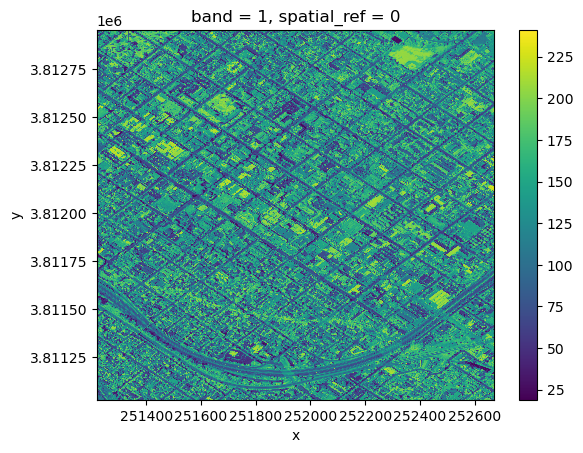

In [5]:
print('Sizes of dimensions:', dict(nir.sizes))

- `band` has length 1, so it makes the `xarray` 3-dimensional for no reason
- `squeeze` removes a dimension of length 1
- `drop=True` removes the coordinates for that dimension

In [6]:
# Original dimensions and coordinates
print(nir.dims, nir.coords, '\n')

# Remove length 1 dimension (band) and its coordinates
nir = nir.squeeze('band', drop = True)
print(nir.dims, nir.coords, '\n')

('band', 'y', 'x') Coordinates:
  * band         (band) int64 8B 1
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 

('y', 'x') Coordinates:
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0 



##`rio` accessor

In [7]:
# Examine raster attributes using rio accessor
print('Number of bands: ', nir.rio.count, '\n')
print('Height: ', nir.rio.height, '\n')
print('Width: ', nir.rio.width, '\n')

print('CRS: ', nir.rio.crs, '\n')

print('Spatial bounding box: ')
print(nir.rio.bounds())

Number of bands:  1 

Height:  3208 

Width:  2419 

CRS:  EPSG:26911 

Spatial bounding box: 
(251218.8, 3811027.2, 252670.19999999998, 3812952.0)


In [8]:
# Import RGB TIF file
fp1 = os.path.join(
                  'data',
                  'NAIP_SB_rgb.tif')

rgb = rioxr.open_rasterio(fp1)
rgb


<xarray.DataArray (band: 3, y: 3208, x: 2419)> Size: 23MB
[23280456 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 19kB 2.512e+05 2.512e+05 ... 2.527e+05 2.527e+05
  * y            (y) float64 26kB 3.813e+06 3.813e+06 ... 3.811e+06 3.811e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

CHeck in 
Obtain this information: shape, number of bands, data  types and the CRS

In [9]:
print('rgb shape: ', rgb.rio.shape)
print('data type: ', rgb.dtype)
print('# of bands: ', rgb.rio.count)
print('CRS: ', rgb.rio.crs)

rgb shape:  (3208, 2419)
data type:  uint8
# of bands:  3
CRS:  EPSG:26911


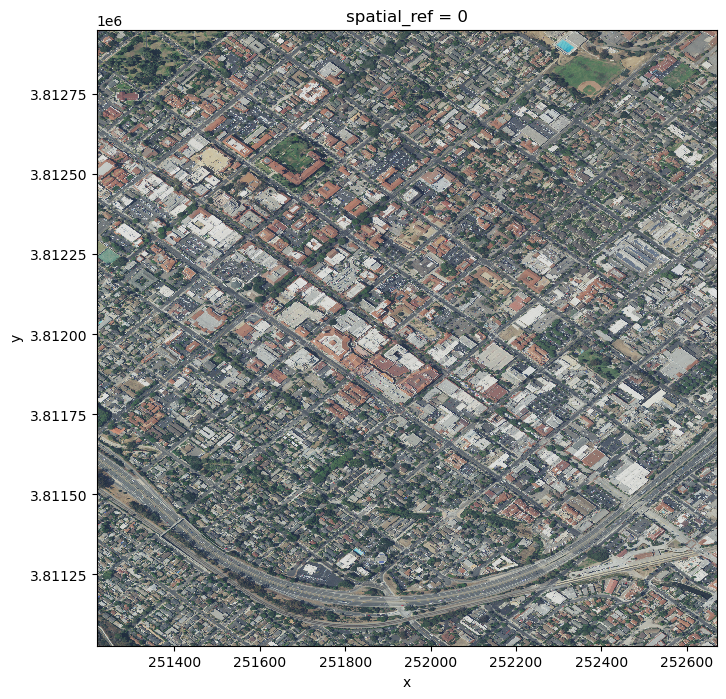

In [10]:
# Plot three bands as RGB layer

rgb_aspect_ratio = rgb.rio.width / rgb.rio.height # Raster's aspect ratio

rgb.plot.imshow(figsize = (8, 8))

In [11]:
fp2 = os.path.join('data', 'SB_aoi.geojson')
aoi = gpd.read_file(fp2)

<Axes: >

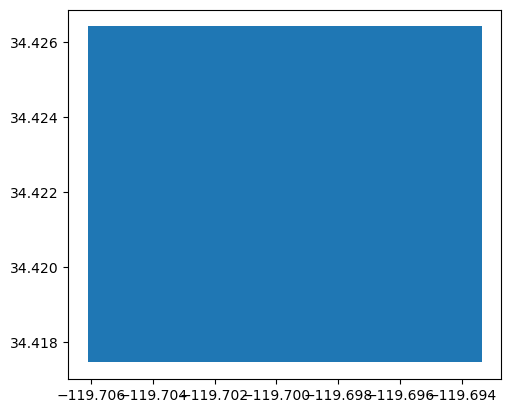

In [12]:
aoi.plot()

In [13]:
print('aoi crs:' , aoi.crs)
print('nir crs: ', nir.rio.crs)
print('rbg crs: ', rgb.rio.crs)

aoi crs: EPSG:4326
nir crs:  EPSG:26911
rbg crs:  EPSG:26911


In [14]:
# ereproject AOI to RGB CRS
aoi = aoi.to_crs(rgb.rio.crs)
assert aoi.crs == rgb.rio.crs

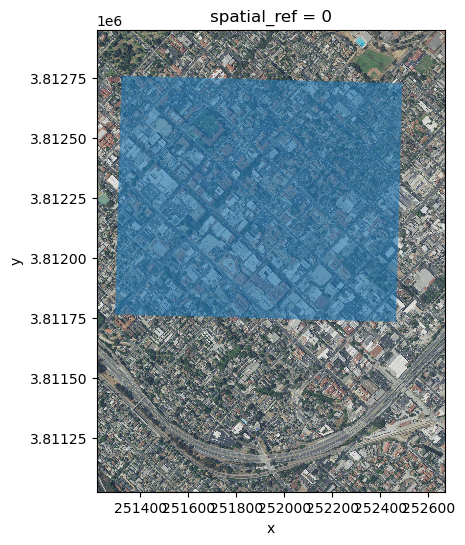

In [15]:
# Plot RGB raster with the AOI overlay
fig, ax = plt.subplots(figsize =(6*rgb_aspect_ratio, 6))
rgb.plot.imshow(ax=ax)
aoi.plot(ax=ax, alpha = 0.6)
plt.show()


In [16]:
aoi.total_bounds

array([ 251294.69376981, 3811735.1717313 ,  252491.02511929,
       3812760.31191696])

In [17]:
rgb.rio.clip_box(*aoi.total_bounds)

<xarray.DataArray (band: 3, y: 1710, x: 1995)> Size: 10MB
[10234350 values with dtype=uint8]
Coordinates:
  * band         (band) int64 24B 1 2 3
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [18]:
rgb_small = rgb.rio.clip_box(*aoi.total_bounds)

In [19]:
nir_small = nir.rio.clip_box(*aoi.total_bounds)

Original shape:  (3208, 2419)
Clipped shape:  (1710, 1995)


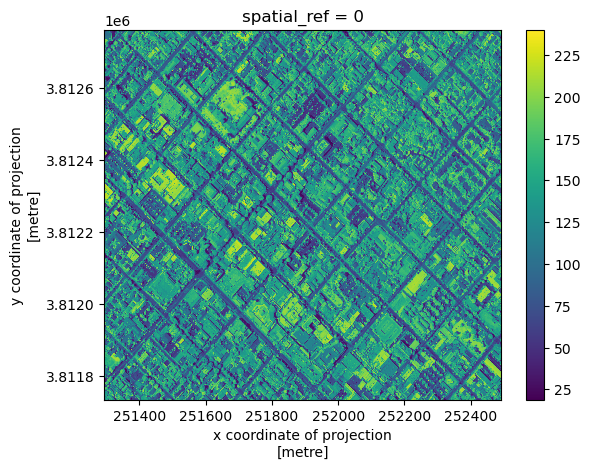

In [20]:
# Examine clipped data
print('Original shape: ', nir.shape)
print('Clipped shape: ', nir_small.shape)

nir_small.plot()

## Raster math

we will compute the **normalized difference vegetation index (NDVI)** over our AOI. 

NDVI checks whther an aras has live green vegetation.

NDVI is always between -1 and 1: values about 0.6 correspon to lush vegetation, water, roofs, pavement, close to zero or negative; sand. rock, snow, 0.1 and below. Generally aboce ~0.1 is vegetation. 

NDVI uses the NIR and red bands:

$$NDVI = \frac{NIR - Red}{NIR + Red}\$$

In [21]:
# Select dimensions by name and coordinate by label 

red_small = rgb_small.sel(band = 1)
red_small

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
    band         int64 8B 1
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

In [22]:
ndvi = (nir_small - red_small)/( nir_small + red_small)

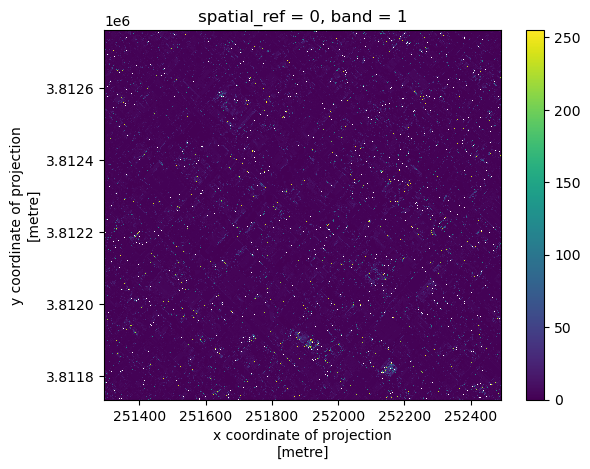

In [23]:
ndvi.plot()

## Data type issues

In [24]:
nir_small 

<xarray.DataArray (y: 1710, x: 1995)> Size: 3MB
[3411450 values with dtype=uint8]
Coordinates:
  * x            (x) float64 16kB 2.513e+05 2.513e+05 ... 2.525e+05 2.525e+05
  * y            (y) float64 14kB 3.813e+06 3.813e+06 ... 3.812e+06 3.812e+06
    spatial_ref  int64 8B 0
Attributes:
    AREA_OR_POINT:  Area
    scale_factor:   1.0
    add_offset:     0.0

we can see he data type for the rasterf is `uint` = 8-bit unsigned integer = only holds integers from 0 to 255

In [25]:
150 + 150

300

In [27]:
np.uint8(150) + np.uint8(150)

/var/folders/7p/_1fy4py55k15fb3n_m7hnh9w0000gn/T/ipykernel_3547/1890984988.py:1: RuntimeWarning: overflow encountered in scalar add
  np.uint8(150) + np.uint8(150)


44

**avoid silent failures!! always verify your results**

In [31]:
# update data type to int64 to peform NDVI calculations

red16 = red_small.astype('int64')
nir16 = nir_small.astype('int64')

print('RED: original dtype:', rgb_small.dtype, '... converted dtype', red16.dtype)
print('RED: original dtype:', nir_small.dtype, '... converted dtype', nir16.dtype)

RED: original dtype: uint8 ... converted dtype int64
RED: original dtype: uint8 ... converted dtype int64


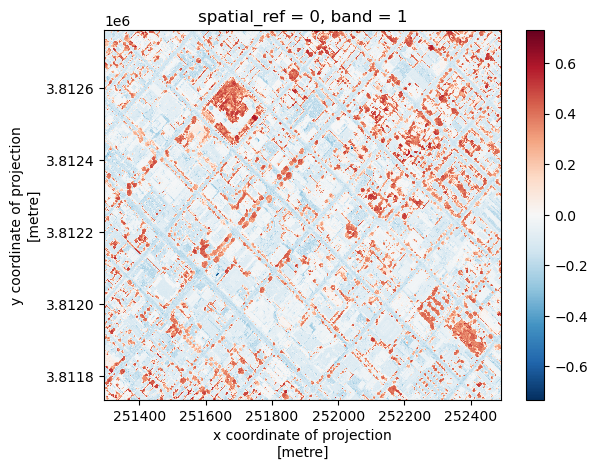

In [33]:
# Calculate NDVI
ndvi = (nir16 - red16)/(nir16 + red16)

ndvi.plot()

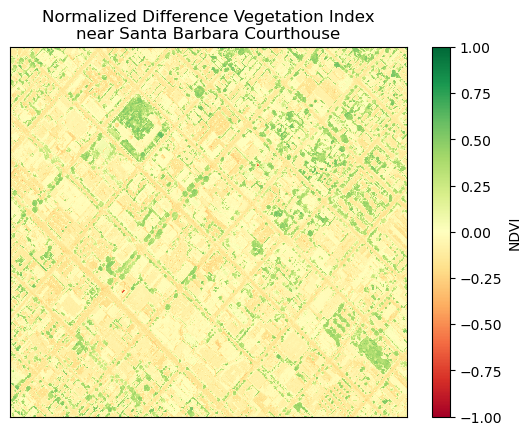

In [34]:
# Plot
fig, ax = plt.subplots()  # Create figure and axes
ndvi.plot(
    ax=ax,
    cmap="RdYlGn",  # Colormap for NDVI
    vmin=-1,  # Minimum value
    vmax=1,   # Maximum value
    cbar_kwargs={"label": "NDVI"}  # Label for color bar
)
ax.set_title("Normalized Difference Vegetation Index\nnear Santa Barbara Courthouse")  # Add title

# Remove axes ticks
ax.set_xticks([])  
ax.set_yticks([])  

# Remove axes labels
ax.set_xlabel("")  
ax.set_ylabel("")  

plt.show()